# Deep Reinforcement Learning with Double Q-learning

**Paper:** van Hasselt, H., Guez, A., & Silver, D. (2016). *Deep Reinforcement Learning with Double Q-learning.* AAAI 2016. [arXiv:1509.06461](https://arxiv.org/abs/1509.06461)

This notebook implements **vanilla DQN** and **Double DQN** from scratch in PyTorch, trains both on CartPole-v1, and compares their Q-value estimates and their returns. The Summary at the end says what this run found.

**Key idea:** standard DQN uses the same network to *select* and to *evaluate* the best next action, which the paper shows leads to overestimated action values. Double DQN lets the **online network** select the action and the **target network** evaluate it.


## 1. Setup & Imports

In [1]:
import atexit
import os
import shutil

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import random
from collections import deque
import warnings
warnings.filterwarnings('ignore')
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Show figures as JPEG at a modest resolution to keep the saved notebook small
set_matplotlib_formats('jpeg')
plt.rcParams['figure.dpi'] = 80

# On Kaggle (detected from its environment), keep a copy of this notebook with its outputs when
# the kernel exits, so `kaggle kernels output` can download the executed version
if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
    atexit.register(lambda: os.path.exists('__notebook__.ipynb')
                    and shutil.copy('__notebook__.ipynb', 'executed_solution.ipynb'))

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cpu')
print(f'Using device: {device}')
print(f'PyTorch version: {torch.__version__}')

Using device: cpu
PyTorch version: 2.11.0+cpu


## 2. Install Environment Library

We use `gymnasium` (the maintained successor to OpenAI Gym) for the CartPole environment.


In [2]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'gymnasium'],
                      stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
import gymnasium as gym
print(f'Gymnasium version: {gym.__version__}')

Gymnasium version: 1.2.0


## 3. Hyperparameters

Both DQN and Double DQN use **identical** hyperparameters for a fair comparison. The paper's Atari setup is much larger (for example a 1M-transition replay memory); the update rule is the same.


In [3]:
# Environment
ENV_NAME = 'CartPole-v1'

# Network
state_dim = 4          # CartPole: [cart_pos, cart_vel, pole_angle, pole_ang_vel]
action_dim = 2         # CartPole: push left (0), push right (1)
hidden_dim = 128       # Hidden layer size

# Training
lr = 1e-3              # Learning rate
gamma = 0.99           # Discount factor
buffer_size = 10_000   # Replay buffer capacity
batch_size = 64        # Minibatch size
target_update_freq = 10  # Episodes between target network updates

# Exploration
epsilon_start = 1.0
epsilon_end = 0.05
epsilon_decay = 0.995

# Training duration
num_episodes = 300     # Training episodes per agent
max_steps = 500        # Max steps per episode (CartPole-v1 cap)

print(f'Environment: {ENV_NAME}')
print(f'State dim: {state_dim}, Action dim: {action_dim}')
print(f'Episodes: {num_episodes}, Max steps: {max_steps}')

Environment: CartPole-v1
State dim: 4, Action dim: 2
Episodes: 300, Max steps: 500


## 4. Environment Setup

CartPole-v1: a pole is attached to a cart moving along a track. The goal is to keep the pole upright for as long as possible, up to 500 steps. The agent receives +1 reward for each step the pole stays up.


In [4]:
env = gym.make(ENV_NAME)
print(f'Observation space: {env.observation_space}')
print(f'Action space: {env.action_space}')

# Test a random episode
state, _ = env.reset(seed=SEED)
env.action_space.seed(SEED)
total_reward = 0
for _ in range(max_steps):
    action = env.action_space.sample()
    state, reward, terminated, truncated, _ = env.step(action)
    total_reward += reward
    if terminated or truncated:
        break
print(f'Random agent reward: {total_reward}')
env.close()

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
Random agent reward: 30.0


## 5. Q-Network

The Q-network approximates Q(s, a) for all actions at once: it takes a state vector and outputs one Q-value per action. The greedy action is the `argmax` over the output.

**Architecture:** an MLP, 4 → 128 → 128 → 2. The paper uses a convolutional network on Atari pixels; the Double Q-learning update is the same.


In [5]:
class QNetwork(nn.Module):
    """MLP that approximates Q(s, a) for all actions."""
    def __init__(self, state_dim, action_dim, hidden_dim):
        super(QNetwork, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )

    def forward(self, x):
        return self.net(x)

# Test
net = QNetwork(state_dim, action_dim, hidden_dim).to(device)
test_state = torch.randn(5, state_dim).to(device)
test_q = net(test_state)
print(f'Input shape: {test_state.shape} → Output shape: {test_q.shape}')
print(f'Q-values for test state:\n{test_q.detach().numpy()}')
total_params = sum(p.numel() for p in net.parameters())
print(f'Total parameters: {total_params}')

Input shape: torch.Size([5, 4]) → Output shape: torch.Size([5, 2])
Q-values for test state:
[[ 0.02270628 -0.01753697]
 [-0.05632246 -0.03068501]
 [ 0.01046171 -0.02518544]
 [ 0.05194935  0.03256334]
 [ 0.0203733   0.01727683]]
Total parameters: 17410


## 6. Experience Replay Buffer

Stores transitions (s, a, r, s', done) and samples random minibatches, which decorrelates the training updates, as in DQN.


In [6]:
class ReplayBuffer:
    """Fixed-size replay buffer with uniform random sampling."""
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (
            torch.FloatTensor(np.array(states)).to(device),
            torch.LongTensor(actions).to(device),
            torch.FloatTensor(rewards).to(device),
            torch.FloatTensor(np.array(next_states)).to(device),
            torch.FloatTensor(dones).to(device)
        )

    def __len__(self):
        return len(self.buffer)

# Test
buf = ReplayBuffer(100)
for _ in range(50):
    s = np.random.randn(state_dim)
    a = random.randint(0, action_dim - 1)
    r = random.random()
    ns = np.random.randn(state_dim)
    d = random.choice([True, False])
    buf.push(s, a, r, ns, d)
s_b, a_b, r_b, ns_b, d_b = buf.sample(8)
print(f'Buffer size: {len(buf)}')
print(f'Sample shapes: states={s_b.shape}, actions={a_b.shape}, rewards={r_b.shape}')

Buffer size: 50
Sample shapes: states=torch.Size([8, 4]), actions=torch.Size([8]), rewards=torch.Size([8])


## 7. ε-Greedy Action Selection

With probability ε, select a random action (exploration); otherwise select the action with the highest Q-value from the **online** network (exploitation).


In [7]:
def select_action(state, policy_net, epsilon, action_dim):
    """Epsilon-greedy action selection using the online network."""
    if random.random() < epsilon:
        return random.randint(0, action_dim - 1)
    with torch.no_grad():
        state_t = torch.FloatTensor(state).unsqueeze(0).to(device)
        q_values = policy_net(state_t)
        return q_values.argmax(dim=1).item()

## 8. Vanilla DQN Optimization Step

The standard DQN target: the **target network** both selects and evaluates the best next action.

$$y = r + \gamma \cdot \max_{a'} Q(s', a'; \theta^-)$$

The paper argues that this is where overestimation comes from: the max picks the action whose value estimate is highest, using the same values that then evaluate it.


In [8]:
def optimize_dqn(policy_net, target_net, replay_buffer, optimizer, batch_size, gamma):
    """One step of vanilla DQN optimization.
    
    Target: y = r + gamma * max_a' Q(s', a'; theta^-)
    The target network BOTH selects (via max) and evaluates the next action.
    """
    if len(replay_buffer) < batch_size:
        return None

    states, actions, rewards, next_states, dones = replay_buffer.sample(batch_size)

    # Current Q-values for taken actions
    current_q = policy_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)

    # Vanilla DQN target: target network selects AND evaluates
    with torch.no_grad():
        next_q = target_net(next_states).max(dim=1)[0]  # max over actions
        target_q = rewards + gamma * next_q * (1 - dones)

    loss = F.smooth_l1_loss(current_q, target_q)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    return loss.item(), current_q.mean().item()

## 9. Double DQN Optimization Step

**The core contribution of the paper.** Decouple action selection from evaluation:

$$y = r + \gamma \cdot Q\left(s', \arg\max_{a'} Q(s', a'; \theta); \theta^-\right)$$

- **Step 1:** the **online network θ** selects the best action: `argmax_a' Q(s', a'; θ)`
- **Step 2:** the **target network θ⁻** evaluates it: `Q(s', a*; θ⁻)`

If the online network overestimates an action, the target network, with its lagged parameters, evaluates it separately. In code, only the line that computes `next_q` changes.


In [9]:
def optimize_double_dqn(policy_net, target_net, replay_buffer, optimizer, batch_size, gamma):
    """One step of Double DQN optimization.
    
    Target: y = r + gamma * Q(s', argmax_a' Q(s', a'; theta); theta^-)
    - Online network theta SELECTS the best next action
    - Target network theta^- EVALUATES that action
    This decoupling reduces overestimation bias.
    """
    if len(replay_buffer) < batch_size:
        return None

    states, actions, rewards, next_states, dones = replay_buffer.sample(batch_size)

    # Current Q-values for taken actions
    current_q = policy_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)

    # Double DQN target: decouple selection from evaluation
    with torch.no_grad():
        # Step 1: Online network selects the best action
        best_actions = policy_net(next_states).argmax(dim=1, keepdim=True)
        # Step 2: Target network evaluates the selected action
        next_q = target_net(next_states).gather(1, best_actions).squeeze(1)
        target_q = rewards + gamma * next_q * (1 - dones)

    loss = F.smooth_l1_loss(current_q, target_q)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    return loss.item(), current_q.mean().item()

## 10. Training Loop

Train vanilla DQN and Double DQN with **identical hyperparameters and random seeds**. We track:
- Episode rewards
- Training losses
- Mean Q-value estimates


In [10]:
def train_agent(agent_type='dqn', num_episodes=300, seed=42):
    """Train a DQN or Double DQN agent on CartPole-v1.
    
    Args:
        agent_type: 'dqn' for vanilla DQN, 'double_dqn' for Double DQN
        num_episodes: number of training episodes
        seed: random seed for reproducibility
    
    Returns:
        dict with rewards, losses, mean_q_values histories
    """
    # Set seeds
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    
    # Create environment, networks, buffer, optimizer
    env = gym.make(ENV_NAME)
    policy_net = QNetwork(state_dim, action_dim, hidden_dim).to(device)
    target_net = QNetwork(state_dim, action_dim, hidden_dim).to(device)
    target_net.load_state_dict(policy_net.state_dict())
    target_net.eval()
    
    replay_buffer = ReplayBuffer(buffer_size)
    optimizer = optim.Adam(policy_net.parameters(), lr=lr)
    
    # Select optimization function
    if agent_type == 'dqn':
        optimize_fn = optimize_dqn
    else:
        optimize_fn = optimize_double_dqn
    
    epsilon = epsilon_start
    episode_rewards = []
    episode_losses = []
    mean_q_history = []
    
    print(f'Training {agent_type.upper()} for {num_episodes} episodes...')
    
    for episode in range(num_episodes):
        state, _ = env.reset(seed=seed + episode)
        total_reward = 0
        ep_losses = []
        ep_q_values = []
        
        for step in range(max_steps):
            # Select action
            action = select_action(state, policy_net, epsilon, action_dim)
            
            # Execute action
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            total_reward += reward
            
            # Store transition
            replay_buffer.push(state, action, reward, next_state, done)
            
            # Optimize
            result = optimize_fn(policy_net, target_net, replay_buffer, 
                                 optimizer, batch_size, gamma)
            if result is not None:
                loss, mean_q = result
                ep_losses.append(loss)
                ep_q_values.append(mean_q)
            
            state = next_state
            if done:
                break
        
        # Decay epsilon
        epsilon = max(epsilon_end, epsilon * epsilon_decay)
        
        # Update target network
        if (episode + 1) % target_update_freq == 0:
            target_net.load_state_dict(policy_net.state_dict())
        
        # Record metrics
        episode_rewards.append(total_reward)
        episode_losses.append(np.mean(ep_losses) if ep_losses else 0)
        mean_q_history.append(np.mean(ep_q_values) if ep_q_values else 0)
        
        if (episode + 1) % 50 == 0:
            avg_reward = np.mean(episode_rewards[-50:])
            avg_q = np.mean(mean_q_history[-50:])
            print(f'  Episode {episode+1}/{num_episodes} | Avg reward (last 50): {avg_reward:.1f} | '
                  f'ε={epsilon:.3f} | Mean Q={avg_q:.2f}')
    
    env.close()
    
    return {
        'rewards': episode_rewards,
        'losses': episode_losses,
        'mean_q_values': mean_q_history,
        'policy_net': policy_net
    }

### Train Vanilla DQN

In [11]:
dqn_results = train_agent(agent_type='dqn', num_episodes=num_episodes, seed=SEED)
print(f'\nDQN final avg reward (last 30): {np.mean(dqn_results["rewards"][-30:]):.1f}')

Training DQN for 300 episodes...


  Episode 50/300 | Avg reward (last 50): 23.8 | ε=0.778 | Mean Q=2.77


  Episode 100/300 | Avg reward (last 50): 36.0 | ε=0.606 | Mean Q=7.46


  Episode 150/300 | Avg reward (last 50): 63.2 | ε=0.471 | Mean Q=12.13


  Episode 200/300 | Avg reward (last 50): 68.6 | ε=0.367 | Mean Q=17.04


  Episode 250/300 | Avg reward (last 50): 51.5 | ε=0.286 | Mean Q=21.81


  Episode 300/300 | Avg reward (last 50): 82.5 | ε=0.222 | Mean Q=26.06

DQN final avg reward (last 30): 102.2


### Train Double DQN

In [12]:
double_dqn_results = train_agent(agent_type='double_dqn', num_episodes=num_episodes, seed=SEED)
print(f'\nDouble DQN final avg reward (last 30): {np.mean(double_dqn_results["rewards"][-30:]):.1f}')

Training DOUBLE_DQN for 300 episodes...


  Episode 50/300 | Avg reward (last 50): 25.6 | ε=0.778 | Mean Q=2.78


  Episode 100/300 | Avg reward (last 50): 37.6 | ε=0.606 | Mean Q=7.40


  Episode 150/300 | Avg reward (last 50): 52.7 | ε=0.471 | Mean Q=11.97


  Episode 200/300 | Avg reward (last 50): 47.1 | ε=0.367 | Mean Q=16.42


  Episode 250/300 | Avg reward (last 50): 71.9 | ε=0.286 | Mean Q=20.49


  Episode 300/300 | Avg reward (last 50): 119.4 | ε=0.222 | Mean Q=24.65

Double DQN final avg reward (last 30): 120.3


## 11. Reward Curve Comparison

Episode rewards for both agents, raw and as a 20-episode rolling mean.


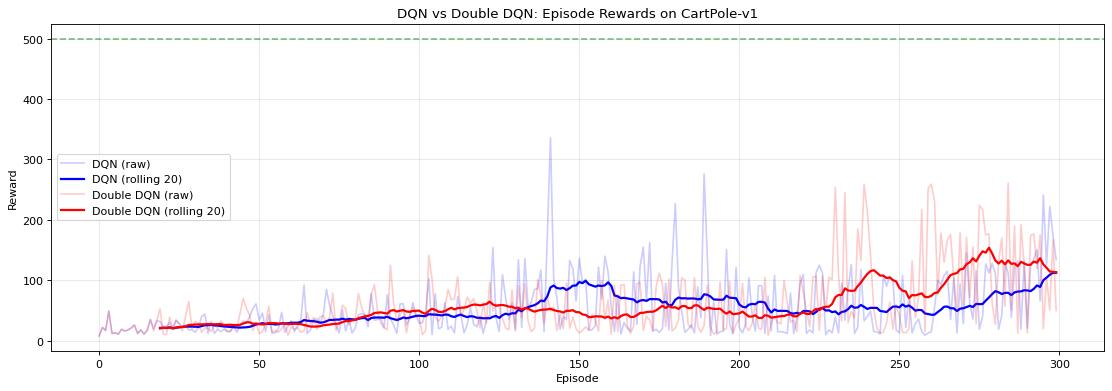

DQN — Final 30-episode avg: 102.2
Double DQN — Final 30-episode avg: 120.3


In [13]:
fig, ax = plt.subplots(figsize=(14, 5))

window = 20
# DQN
ax.plot(dqn_results['rewards'], alpha=0.2, color='blue', label='DQN (raw)')
if len(dqn_results['rewards']) >= window:
    dqn_smooth = np.convolve(dqn_results['rewards'], np.ones(window)/window, mode='valid')
    ax.plot(range(window-1, len(dqn_results['rewards'])), dqn_smooth, 
            color='blue', linewidth=2, label=f'DQN (rolling {window})')

# Double DQN
ax.plot(double_dqn_results['rewards'], alpha=0.2, color='red', label='Double DQN (raw)')
if len(double_dqn_results['rewards']) >= window:
    ddqn_smooth = np.convolve(double_dqn_results['rewards'], np.ones(window)/window, mode='valid')
    ax.plot(range(window-1, len(double_dqn_results['rewards'])), ddqn_smooth, 
            color='red', linewidth=2, label=f'Double DQN (rolling {window})')

ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.set_title('DQN vs Double DQN: Episode Rewards on CartPole-v1')
ax.legend()
ax.grid(True, alpha=0.3)
ax.axhline(y=500, color='green', linestyle='--', alpha=0.5, label='Max reward')
plt.tight_layout()
plt.show()

print(f'DQN — Final 30-episode avg: {np.mean(dqn_results["rewards"][-30:]):.1f}')
print(f'Double DQN — Final 30-episode avg: {np.mean(double_dqn_results["rewards"][-30:]):.1f}')

## 12. Q-Value Estimates During Training

The paper predicts that vanilla DQN will show higher (more overestimated) Q-values than Double DQN. Here we compare the mean Q-value of the sampled training batches.

For scale: with γ = 0.99 and at most 500 steps of +1 reward, the largest possible discounted return is (1 − 0.99⁵⁰⁰) / (1 − 0.99) ≈ 99.3. Section 15 compares predicted values with actual returns directly.


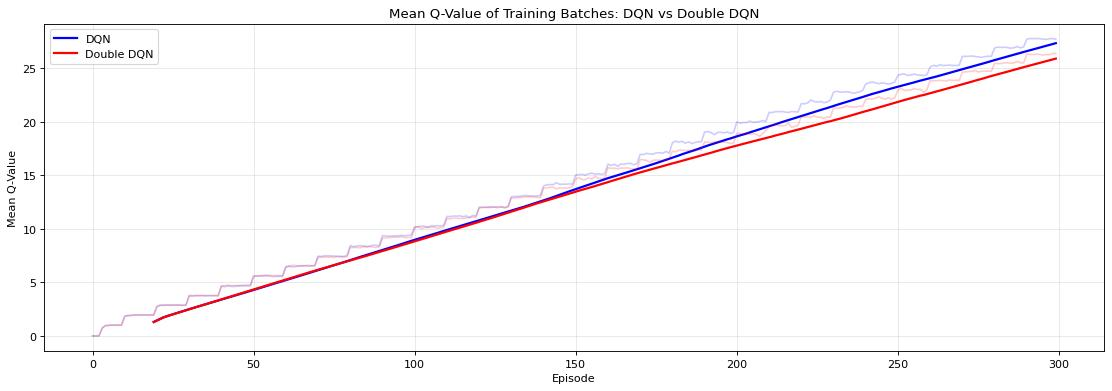

DQN mean Q-value (last 30 episodes): 26.91
Double DQN mean Q-value (last 30 episodes): 25.48
Difference (DQN - Double DQN): 1.43
Relative difference: 5.6% of the Double DQN value


In [14]:
fig, ax = plt.subplots(figsize=(14, 5))

window = 20
# DQN Q-values
ax.plot(dqn_results['mean_q_values'], alpha=0.2, color='blue')
if len(dqn_results['mean_q_values']) >= window:
    dqn_q_smooth = np.convolve(dqn_results['mean_q_values'], np.ones(window)/window, mode='valid')
    ax.plot(range(window-1, len(dqn_results['mean_q_values'])), dqn_q_smooth, 
            color='blue', linewidth=2, label='DQN')

# Double DQN Q-values
ax.plot(double_dqn_results['mean_q_values'], alpha=0.2, color='red')
if len(double_dqn_results['mean_q_values']) >= window:
    ddqn_q_smooth = np.convolve(double_dqn_results['mean_q_values'], np.ones(window)/window, mode='valid')
    ax.plot(range(window-1, len(double_dqn_results['mean_q_values'])), ddqn_q_smooth, 
            color='red', linewidth=2, label='Double DQN')

ax.set_xlabel('Episode')
ax.set_ylabel('Mean Q-Value')
ax.set_title('Mean Q-Value of Training Batches: DQN vs Double DQN')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

dqn_final_q = np.mean(dqn_results['mean_q_values'][-30:])
ddqn_final_q = np.mean(double_dqn_results['mean_q_values'][-30:])
print(f'DQN mean Q-value (last 30 episodes): {dqn_final_q:.2f}')
print(f'Double DQN mean Q-value (last 30 episodes): {ddqn_final_q:.2f}')
print(f'Difference (DQN - Double DQN): {dqn_final_q - ddqn_final_q:.2f}')
print(f'Relative difference: {100 * (dqn_final_q - ddqn_final_q) / ddqn_final_q:.1f}% of the Double DQN value')

## 13. Loss Curve Comparison

The Huber (smooth L1) loss for both agents.


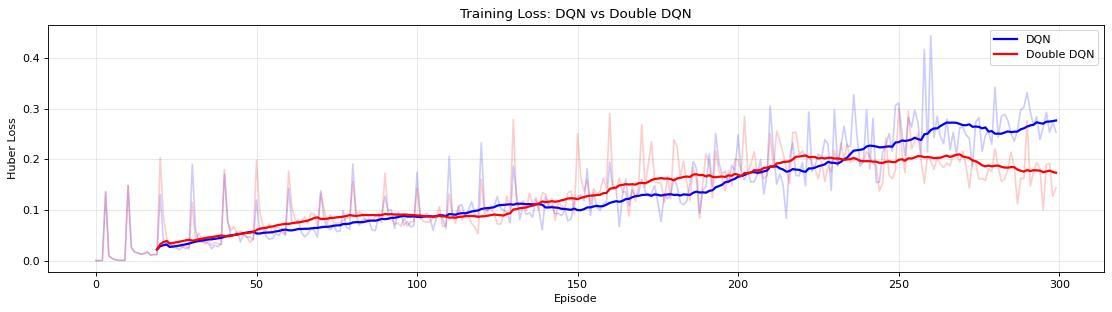

In [15]:
fig, ax = plt.subplots(figsize=(14, 4))

window = 20
ax.plot(dqn_results['losses'], alpha=0.2, color='blue')
if len(dqn_results['losses']) >= window:
    dqn_l_smooth = np.convolve(dqn_results['losses'], np.ones(window)/window, mode='valid')
    ax.plot(range(window-1, len(dqn_results['losses'])), dqn_l_smooth, 
            color='blue', linewidth=2, label='DQN')

ax.plot(double_dqn_results['losses'], alpha=0.2, color='red')
if len(double_dqn_results['losses']) >= window:
    ddqn_l_smooth = np.convolve(double_dqn_results['losses'], np.ones(window)/window, mode='valid')
    ax.plot(range(window-1, len(double_dqn_results['losses'])), ddqn_l_smooth, 
            color='red', linewidth=2, label='Double DQN')

ax.set_xlabel('Episode')
ax.set_ylabel('Huber Loss')
ax.set_title('Training Loss: DQN vs Double DQN')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 14. Evaluation: Greedy Policy

Run both trained agents with ε = 0 (pure greedy, no exploration) for 10 episodes and compare their returns.


Greedy Policy Evaluation (10 episodes):
  DQN       — Mean: 183.8, Std: 18.2, Min: 149.0, Max: 205.0
  Double DQN — Mean: 152.7, Std: 5.0, Min: 146.0, Max: 165.0


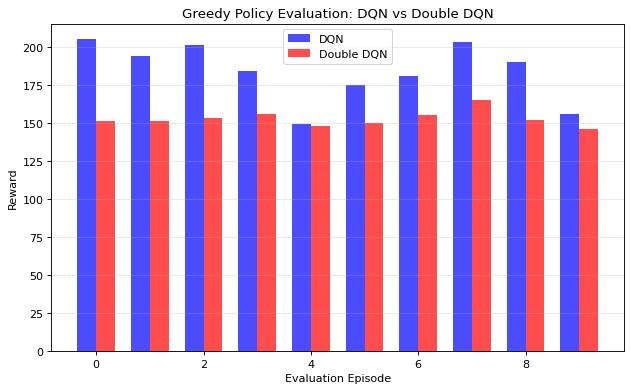

In [16]:
def evaluate_agent(policy_net, num_eval_episodes=10, seed=1000):
    """Evaluate a trained agent with greedy policy (epsilon=0)."""
    env = gym.make(ENV_NAME)
    rewards = []
    for ep in range(num_eval_episodes):
        state, _ = env.reset(seed=seed + ep)
        total_reward = 0
        with torch.no_grad():
            for step in range(max_steps):
                state_t = torch.FloatTensor(state).unsqueeze(0).to(device)
                q_values = policy_net(state_t)
                action = q_values.argmax(dim=1).item()
                state, reward, terminated, truncated, _ = env.step(action)
                total_reward += reward
                if terminated or truncated:
                    break
        rewards.append(total_reward)
    env.close()
    return rewards

dqn_eval = evaluate_agent(dqn_results['policy_net'])
ddqn_eval = evaluate_agent(double_dqn_results['policy_net'])

print('Greedy Policy Evaluation (10 episodes):')
print(f'  DQN       — Mean: {np.mean(dqn_eval):.1f}, Std: {np.std(dqn_eval):.1f}, '
      f'Min: {np.min(dqn_eval)}, Max: {np.max(dqn_eval)}')
print(f'  Double DQN — Mean: {np.mean(ddqn_eval):.1f}, Std: {np.std(ddqn_eval):.1f}, '
      f'Min: {np.min(ddqn_eval)}, Max: {np.max(ddqn_eval)}')

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(10)
width = 0.35
ax.bar(x - width/2, dqn_eval, width, label='DQN', color='blue', alpha=0.7)
ax.bar(x + width/2, ddqn_eval, width, label='Double DQN', color='red', alpha=0.7)
ax.set_xlabel('Evaluation Episode')
ax.set_ylabel('Reward')
ax.set_title('Greedy Policy Evaluation: DQN vs Double DQN')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

## 15. Predicted Q-Values vs Actual Returns

For 50 start states, compare each agent's predicted Q(s, greedy action) with the discounted return it actually gets by following its greedy policy:
1. Record the predicted Q(s, greedy action)
2. Follow the greedy policy from that state and add up the discounted rewards
3. Compare: Q above the actual return means overestimation, Q below means underestimation


In [17]:
def measure_overestimation(policy_net, num_samples=50, seed=2000):
    """Measure Q-value overestimation by comparing predicted Q to actual returns."""
    env = gym.make(ENV_NAME)
    predicted_qs = []
    actual_returns = []
    
    for i in range(num_samples):
        state, _ = env.reset(seed=seed + i)
        
        # Get predicted Q-value for greedy action
        with torch.no_grad():
            state_t = torch.FloatTensor(state).unsqueeze(0).to(device)
            q_values = policy_net(state_t)
            greedy_action = q_values.argmax(dim=1).item()
            predicted_q = q_values[0, greedy_action].item()
        
        # Execute greedy policy and observe actual discounted return
        actual_return = 0
        discount = 1.0
        current_state = state
        with torch.no_grad():
            for step in range(max_steps):
                cs_t = torch.FloatTensor(current_state).unsqueeze(0).to(device)
                qv = policy_net(cs_t)
                action = qv.argmax(dim=1).item()
                current_state, reward, terminated, truncated, _ = env.step(action)
                actual_return += discount * reward
                discount *= gamma
                if terminated or truncated:
                    break
        
        predicted_qs.append(predicted_q)
        actual_returns.append(actual_return)
    
    env.close()
    return np.array(predicted_qs), np.array(actual_returns)

dqn_pred, dqn_actual = measure_overestimation(dqn_results['policy_net'], num_samples=50)
ddqn_pred, ddqn_actual = measure_overestimation(double_dqn_results['policy_net'], num_samples=50)

dqn_overest = dqn_pred - dqn_actual
ddqn_overest = ddqn_pred - ddqn_actual

print('Q-Value Overestimation Analysis (50 sampled states):')
print(f'  DQN        — Avg predicted Q: {np.mean(dqn_pred):.2f}, Avg actual return: {np.mean(dqn_actual):.2f}, '
      f'Q minus return: {np.mean(dqn_overest):.2f}')
print(f'  Double DQN — Avg predicted Q: {np.mean(ddqn_pred):.2f}, Avg actual return: {np.mean(ddqn_actual):.2f}, '
      f'Q minus return: {np.mean(ddqn_overest):.2f}')
print('  (positive = overestimation, negative = underestimation)')

Q-Value Overestimation Analysis (50 sampled states):
  DQN        — Avg predicted Q: 27.99, Avg actual return: 86.86, Q minus return: -58.87
  Double DQN — Avg predicted Q: 27.16, Avg actual return: 78.79, Q minus return: -51.63
  (positive = overestimation, negative = underestimation)


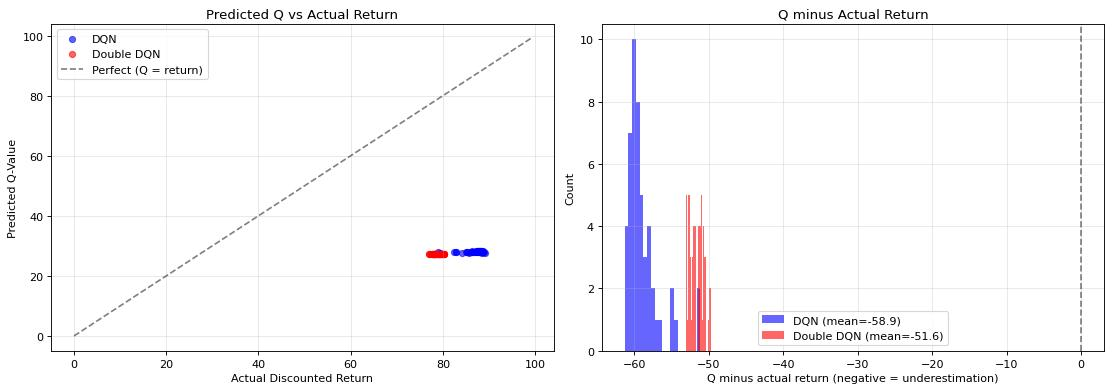

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter: predicted vs actual
ax = axes[0]
ax.scatter(dqn_actual, dqn_pred, alpha=0.6, color='blue', label='DQN', s=30)
ax.scatter(ddqn_actual, ddqn_pred, alpha=0.6, color='red', label='Double DQN', s=30)
max_val = max(np.max(dqn_pred), np.max(ddqn_pred), np.max(dqn_actual)) + 10
ax.plot([0, max_val], [0, max_val], 'k--', alpha=0.5, label='Perfect (Q = return)')
ax.set_xlabel('Actual Discounted Return')
ax.set_ylabel('Predicted Q-Value')
ax.set_title('Predicted Q vs Actual Return')
ax.legend()
ax.grid(True, alpha=0.3)

# Overestimation histogram
ax = axes[1]
ax.hist(dqn_overest, bins=20, alpha=0.6, color='blue', label=f'DQN (mean={np.mean(dqn_overest):.1f})')
ax.hist(ddqn_overest, bins=20, alpha=0.6, color='red', label=f'Double DQN (mean={np.mean(ddqn_overest):.1f})')
ax.axvline(x=0, color='black', linestyle='--', alpha=0.5)
ax.set_xlabel('Q minus actual return (negative = underestimation)')
ax.set_ylabel('Count')
ax.set_title('Q minus Actual Return')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 16. Summary

### What the run above shows

Results on this short CartPole run change from run to run, so the printed outputs above are this run's own numbers. The figures below come from two earlier runs of the same code (not saved here). Each of those two outcomes has also come up again in later runs, so expect one of them above.

- **Neither agent was consistently better.** In one earlier run, Double DQN ended training ahead (last-30-episode average 120.3 vs 102.2) but scored lower in the greedy evaluation (152.7 vs 183.8). In the other, it was behind on both (60.2 vs 91.6 in training, 107.6 vs 111.9 greedy).
- **The Q-value gap was small.** At the end of training, DQN's mean Q-value was about 1.4 higher than Double DQN's in both earlier runs (about 5%). The two curves were still rising almost in a straight line at episode 300, so neither had settled.
- **Both agents underestimated, not overestimated.** Their predicted Q-values were 40 to 60 below the discounted returns they actually got (for example −58.9 for DQN and −51.6 for Double DQN). After only 300 episodes the values have not caught up with how well the agents already play, so this run cannot show the overestimation the paper is about.
- **What it does show:** both agents' rewards rise during training (see the reward curves above), and the code shows exactly where Double DQN changes the target. Testing the paper's claim would need longer training, so the values converge, and repeated seeds.
